# Email Spam Detection

**Objective :**
To build a machine learning model that can classify emails or messages as Spam or Not Spam (Ham).

### Project Overview
This project involves loading a dataset, cleaning text data, exploring message patterns, converting text into numerical features, training machine learning models, and evaluating their performance.

## 1.Import Libraries

We import the required libraries for data manipulation, text preprocessing, feature extraction, machine learning, model evaluation and visualization.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


## 2. Download the Dataset

In this step, we download the SMS Spam Collection dataset from the UCI Machine Learning Repository.

The dataset contains SMS messages classified into two categories:

- **Ham:** Legitimate messages.
- **Spam:** Unwanted or fraudulent messages.

We use Python's `urllib` library to download the dataset automatically and `zipfile` to extract the dataset file.

The extracted file, `SMSSpamCollection`, will be used for our spam detection project.

In [4]:
import requests
import zipfile
import io
import os

# Dataset URL
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

# Download dataset
response = requests.get(url, timeout=30)
response.raise_for_status()

# Extract ZIP file
with zipfile.ZipFile(io.BytesIO(response.content)) as zip_ref:
    zip_ref.extract("SMSSpamCollection", ".")

print("Dataset downloaded successfully!")

# Check file
print("File exists:", os.path.exists("SMSSpamCollection"))

Dataset downloaded successfully!
File exists: True


## 3.Load Dataset


In [5]:
df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="latin-1"
)

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


The dataset contains two important columns:
- label: Indicates whether a message is spam or ham.
- message: Contains the actual text of the message.
We use tab separation because the dataset is stored in a tab-separated format.

In [8]:
# Display first five rows
display(df.head())

# Check dataset shape
print("Dataset Shape:", df.shape)

# Check column information
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Dataset Shape: (5572, 2)
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB

Missing Values:
label      0
message    0
dtype: int64

Duplicate Rows: 403


## 4. Data Cleaning

In this step, we remove duplicate records from the dataset to avoid repeated messages affecting our analysis and model training.

We also reset the index after removing duplicates to maintain a clean and organized dataset.

In [10]:
# Remove duplicate rows
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

# Check updated dataset shape
df.shape

(5169, 2)

### Check Class Distribution

In this step, we examine the distribution of spam and ham messages in our dataset.

We calculate the number and percentage of messages in each category and visualize the distribution using a bar chart.

This helps us understand whether our dataset is balanced or imbalanced.

In [11]:
# Count spam and ham messages
df["label"].value_counts()

label
ham     4516
spam     653
Name: count, dtype: int64

In [12]:
# Calculate percentage of each category
df["label"].value_counts(normalize=True) * 100

label
ham     87.366996
spam    12.633004
Name: proportion, dtype: float64

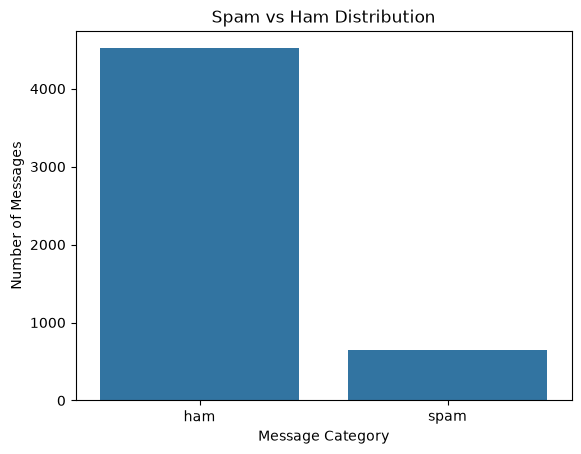

In [13]:
# Plot class distribution
sns.countplot(data=df, x="label")

plt.title("Spam vs Ham Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.show()

### Class Distribution Analysis

The dataset contains approximately 87.37% ham messages and 12.63% spam messages.

This indicates that the dataset is imbalanced because legitimate messages significantly outnumber spam messages.

Therefore, precision, recall and F1-score will be important evaluation metrics when comparing our classification models.

### Convert Labels into Numerical Values

Machine learning models require numerical labels for classification.

We convert the categorical labels into binary values:

- Ham = 0
- Spam = 1

This allows the classification algorithms to distinguish between the two categories.

In [14]:
df["label"] = df["label"].map({"ham": 0, "spam": 1})

df.head()

,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


### Text Preprocessing

Text preprocessing prepares messages for machine learning by making the text more consistent and removing unnecessary characters.

In this step, we convert messages to lowercase, remove punctuation, and remove extra spaces.

In [15]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_message"] = df["message"].apply(clean_text)

df[["message", "clean_message"]].head()

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


## 5. Train-Test Split

In this step, we divide our dataset into two parts:

- **Training data (80%):** Used to train the machine learning model.
- **Testing data (20%):** Used to evaluate the model on unseen messages.

This helps us understand how well our model can classify new messages.

In [16]:
from sklearn.model_selection import train_test_split

# Separate messages and labels
X = df["clean_message"]
y = df["label"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [17]:
print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 4135
Testing data: 1034


## 6. TF-IDF Vectorization

TF-IDF (Term Frequency–Inverse Document Frequency) is a technique used to convert text messages into numerical values.

It assigns importance to words based on how frequently they appear in a message and how common they are across all messages.

This allows machine learning models to work with text data.

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(stop_words="english")

# Convert training messages into numerical features
X_train_tfidf = tfidf.fit_transform(X_train)

# Convert testing messages using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

In [19]:
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (4135, 8151)
Testing data shape: (1034, 8151)


## 7. Model Training 
### 7.1 Multinomial Naive Bayes

Multinomial Naive Bayes is a machine learning algorithm commonly used for text classification.

It uses probability to predict whether a message belongs to a particular category.

In our project, it will classify messages as:

- 0 = Ham
- 1 = Spam

In [40]:
from sklearn.naive_bayes import MultinomialNB

# Create the Naive Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

# Predict test messages
nb_predictions = nb_model.predict(X_test_tfidf)
# Train the model


print("Naive Bayes Model Trained Successfully!")

Naive Bayes Model Trained Successfully!


In [ ]:
print(nb_predictions[:10])

[0 0 0 0 0 0 0 0 0 0]


### 7.2 Logistic Regression

Logistic Regression is a supervised machine learning algorithm used for classification.

It estimates the probability that a message belongs to a particular category.

In our project, it will classify messages into:

- 0 = Ham
- 1 = Spam

In [25]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression Model Trained Successfully!")

# Predict test messages
lr_predictions = lr_model.predict(X_test_tfidf)

Logistic Regression Model Trained Successfully!


In [26]:
print(lr_predictions[:10])

[0 0 0 0 0 0 0 0 0 0]


## 8. Model Evaluation

We evaluate the performance of our trained machine learning models using different classification metrics.

We will use:

- Accuracy
- Precision
- Recall
- F1-score
- confusion matrix

These metrics help us understand how correctly our models identify spam and legitimate messages.

### 8.1 Naive Bayes 

In [27]:
# Evaluate Naive Bayes model
print("Naive Bayes Evaluation")

print("Accuracy:", accuracy_score(y_test, nb_predictions))
print("Precision:", precision_score(y_test, nb_predictions))
print("Recall:", recall_score(y_test, nb_predictions))
print("F1-score:", f1_score(y_test, nb_predictions))

Naive Bayes Evaluation
Accuracy: 0.9632495164410058
Precision: 1.0
Recall: 0.7099236641221374
F1-score: 0.8303571428571429


#### Naive Bayes Model Evaluation Analysis

The Multinomial Naive Bayes model achieved an accuracy of 96.32%.

The model obtained 100% precision, meaning that all messages predicted as spam were actually spam.

However, its recall was 70.99%, indicating that the model failed to identify approximately 29% of actual spam messages.

The F1-score was 83.04%, showing a balance between precision and recall.

Overall, the model performed well, but its spam detection recall could be improved.

### 8.2 Logistic Regression

In [29]:
# Evaluate Logistic Regression model
print("Logistic Regression Evaluation")

print("Accuracy:", accuracy_score(y_test, lr_predictions))
print("Precision:", precision_score(y_test, lr_predictions))
print("Recall:", recall_score(y_test, lr_predictions))
print("F1-score:", f1_score(y_test, lr_predictions))

Logistic Regression Evaluation
Accuracy: 0.9497098646034816
Precision: 0.9759036144578314
Recall: 0.6183206106870229
F1-score: 0.7570093457943925


#### Logistic Regression Model Evaluation Analysis

The Logistic Regression model achieved an accuracy of 94.97%.

It obtained 97.59% precision, meaning that most messages predicted as spam were actually spam.

However, its recall was 61.83%, indicating that the model failed to identify approximately 38% of actual spam messages.

The F1-score was 75.70%, showing the balance between precision and recall.

Overall, Logistic Regression performed well, but its ability to detect actual spam messages could be improved.

### Confusion Matrix

A confusion matrix is used to evaluate the performance of a classification model.

It shows four possible outcomes:

- **True Positive (TP):** Actual spam correctly predicted as spam.
- **True Negative (TN):** Actual ham correctly predicted as ham.
- **False Positive (FP):** Actual ham incorrectly predicted as spam.
- **False Negative (FN):** Actual spam incorrectly predicted as ham.

We will create confusion matrices for both Naive Bayes and Logistic Regression to compare their classification results.

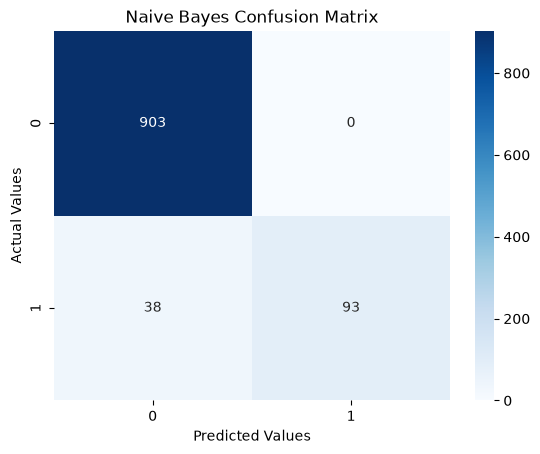

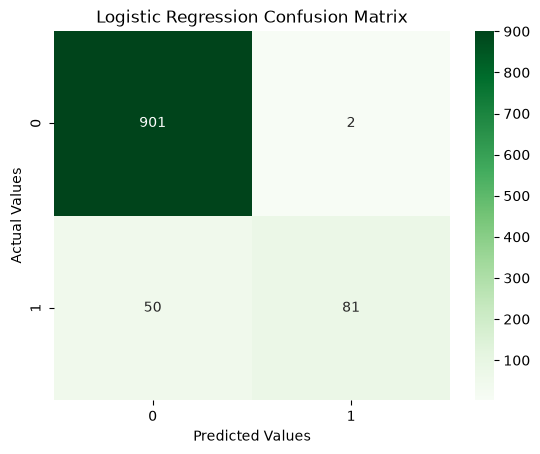

In [33]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Confusion Matrix for Naive Bayes
nb_cm = confusion_matrix(y_test, nb_predictions)

sns.heatmap(nb_cm, annot=True, fmt="d", cmap="Blues")
plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()


# Confusion Matrix for Logistic Regression
lr_cm = confusion_matrix(y_test, lr_predictions)

sns.heatmap(lr_cm, annot=True, fmt="d", cmap="Greens")
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

### Confusion Matrix Analysis

The confusion matrices show the classification performance of both models.

**Naive Bayes:**

The model correctly classified 903 ham messages and 93 spam messages. It incorrectly classified 38 spam messages as ham and did not classify any ham messages as spam.

**Logistic Regression:**

The model correctly classified 901 ham messages and 81 spam messages. It incorrectly classified 50 spam messages as ham and 2 ham messages as spam.

**Overall Analysis:**

Naive Bayes performed better than Logistic Regression in this experiment. It correctly detected more spam messages (93 compared to 81) and made fewer classification errors.

Therefore, Naive Bayes demonstrated better spam detection performance on the testing dataset.

## 9. Model Comparison

In this project, we trained and evaluated two machine learning classifiers: Multinomial Naive Bayes and Logistic Regression.

Both models achieved good performance on the SMS Spam Collection dataset. However, Multinomial Naive Bayes performed better across all four evaluation metrics.

| Evaluation Metric | Naive Bayes | Logistic Regression |
|---|---:|---:|
| Accuracy | 96.32% | 94.97% |
| Precision | 100% | 97.59% |
| Recall | 70.99% | 61.83% |
| F1-score | 83.04% | 75.70% |

The confusion matrices also support these results. Naive Bayes correctly identified 93 spam messages, while Logistic Regression identified 81 spam messages.

Furthermore, Naive Bayes missed 38 spam messages, compared to 50 missed by Logistic Regression.

**Conclusion:**

Multinomial Naive Bayes performed better than Logistic Regression in this experiment. It achieved higher accuracy, precision, recall, and F1-score while detecting more spam messages.

Therefore, Multinomial Naive Bayes is the better-performing model among the two classifiers tested in this project.

## 10.Why Is Recall Important for Spam Detection?

Recall is particularly important in spam detection because it measures how many actual spam messages are correctly identified by the model.

A low recall means that many spam messages are incorrectly classified as legitimate messages (ham).

These missed spam messages may reach the user's inbox, potentially exposing them to unwanted advertisements, phishing attempts, and fraudulent messages.

Therefore, a spam detection model should aim for high recall so that it can identify as many spam messages as possible.

However, precision is also important because legitimate messages should not be incorrectly marked as spam.

## 11.WordCloud Visualisations.

In [39]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### Import Libraries

In [35]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

### Spam WordCloud Visualization

A WordCloud represents text visually, where frequently occurring words appear larger than less frequent words.

In this step, we create a WordCloud using spam messages to identify the most frequently occurring words in spam.

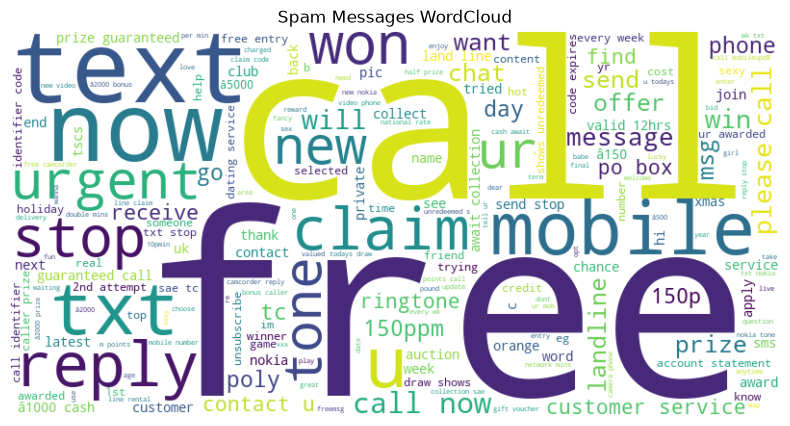

In [36]:
# Select spam messages
spam_messages = df[df["label"] == 1]["clean_message"]

# Combine all spam messages into one text
spam_text = " ".join(spam_messages)

# Generate WordCloud
spam_wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(spam_text)

# Display WordCloud
plt.figure(figsize=(10, 5))
plt.imshow(spam_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Spam Messages WordCloud")
plt.show()

### Ham WordCloud Visualization

In this step, we create a WordCloud using legitimate (ham) messages to identify the most frequently occurring words.

This visualization helps us understand the common vocabulary used in normal text messages.

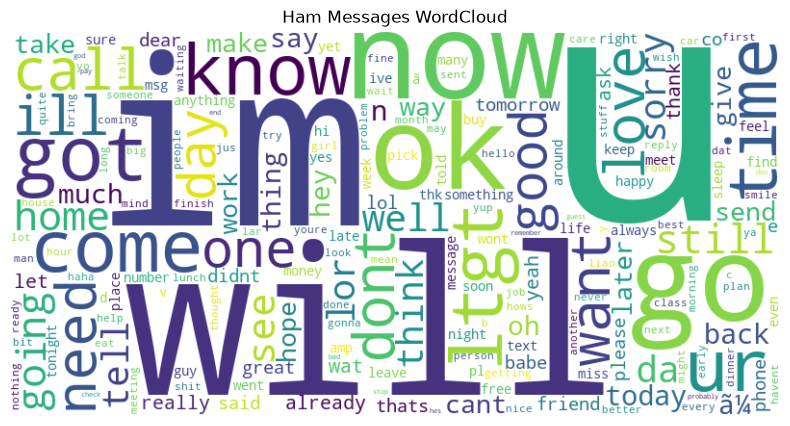

In [37]:
# Select ham messages
ham_messages = df[df["label"] == 0]["clean_message"]

# Combine all ham messages into one text
ham_text = " ".join(ham_messages)

# Generate WordCloud
ham_wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(ham_text)

# Display WordCloud
plt.figure(figsize=(10, 5))
plt.imshow(ham_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Ham Messages WordCloud")
plt.show()